# Thrombectomy descriptive statistics

## Load and filter data

**What this cell does:** Imports the libraries used in this notebook: matplotlib for plotting, NumPy for numerical work and pandas for data handling.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

**What this cell does:** Loads the cleaned SAMueL-3 SSNAP data (`cleaned_data.csv`), keeps admissions from `min_year` to `max_year` inclusive (currently 2023–2025) as `data_filtered`, and shows the proportion of all these admissions who received thrombectomy.

In [14]:
all_data = pd.read_csv("../data/sam3/cleaned_data.csv", low_memory=False)

# Select years to include (inclusive)
min_year = 2024
max_year = 2025

# Get data for selected years
mask = (all_data['year'] >= min_year) & (all_data['year'] <= max_year)
data_filtered = all_data[mask]

# Get the avergae thrombectomy of all patients
data_filtered['thrombectomy'].mean()


np.float64(0.043596961629748514)

**Results:** 4.4% of all stroke admissions in the selected years received thrombectomy.

**What this cell does:** Restricts `data_filtered` to ischaemic stroke (`infarction` = 1) and recalculates the proportion receiving thrombectomy.

In [3]:
# Limit to infarction == 1
data_filtered = data_filtered[data_filtered['infarction'] == 1]
data_filtered['thrombectomy'].mean()

np.float64(0.05022230265442575)

**Results:** 5.0% of ischaemic stroke admissions received thrombectomy.

**What this cell does:** Restricts to more severe strokes (NIHSS `stroke_severity` > 10) and shows the proportion of these patients receiving thrombectomy. This is the population used for the thrombectomy rates below.

In [4]:
# Limit to stroke_severity > 10
data_filtered = data_filtered[data_filtered['stroke_severity'] > 10]
data_filtered['thrombectomy'].mean()

np.float64(0.18982936143471746)

**Results:** 19.0% of ischaemic stroke patients with NIHSS > 10 received thrombectomy.

**What this cell does:** Calculates the proportion of patients receiving thrombectomy, split by whether they first attended a thrombectomy centre (`thrombectomy_centre` = 1) or not (0).

In [5]:
# Get proportion thrombectomy by thrombectomy_centre
proportion_thrombectomy = data_filtered.groupby('thrombectomy_centre')['thrombectomy'].mean()
proportion_thrombectomy


thrombectomy_centre
0.0    0.164513
1.0    0.246742
Name: thrombectomy, dtype: float64

**Results:** Patients who first attended a thrombectomy centre were more likely to receive thrombectomy: 24.7% compared with 16.5% of those who first attended a non-thrombectomy centre.

**What this cell does:** Counts patients, and the proportion receiving thrombectomy, split by first-attended centre type *and* by whether they also received thrombolysis. The index is renamed and reset to give a flat, readable table.

In [6]:
df_split = data_filtered.groupby(
    ["thrombectomy_centre", "thrombolysis"]
).agg({"thrombectomy": ["mean", "count"]})

# Make df_split index more readable
df_split.index = df_split.index.set_names(["Thrombectomy Centre", "Thrombolysis"])

# Unmerge index
df_split = df_split.reset_index()

df_split


Thrombectomy Centre Thrombolysis thrombectomy       
                                           mean  count
0                 0.0            0     0.111943  19903
1                 0.0            1     0.284324   8733
2                 1.0            0     0.191162   9165
3                 1.0            1     0.389309   3573

**Results:** Proportion receiving thrombectomy (and number of patients) by first-attended centre type and thrombolysis:

| First attended | No thrombolysis | Thrombolysis |
|---|---|---|
| Non-thrombectomy centre | 11.2% (n = 19,903) | 28.4% (n = 8,733) |
| Thrombectomy centre | 19.1% (n = 9,165) | 38.9% (n = 3,573) |

Thrombectomy rates are higher at thrombectomy centres both with and without thrombolysis. Within each type of centre, patients who received thrombolysis were more than twice as likely to also receive thrombectomy. This probably reflects patients arriving earlier and being more suitable for reperfusion treatment, not an effect of thrombolysis itself. The proportion receiving thrombolysis was similar: 30.5% at non-thrombectomy centres and 28.0% at thrombectomy centres. In total, 41,374 patients have a known first-attended centre type.

## Descriptive statistics for all those receiving thrombectomy within 12 hours

**What this cell does:** Keeps only patients whose arrival-to-thrombectomy time is 12 hours (720 min) or less.

**Note:** patients who did not have thrombectomy have no arrival-to-thrombectomy time (NaN), and NaN fails the `<= 720` test, so this filter also removes every non-thrombectomy patient. From this cell onwards, `data_filtered` contains **only thrombectomy patients treated within 12 hours of arrival**.

In [7]:
# Clip arrival-to-thrombectomy times at 12 hours
mask = data_filtered['arrival_to_thrombectomy_time'] <= 720
data_filtered = data_filtered[mask]

**Results:** No output is shown. After this filter, 7,511 thrombectomy patients with a known first-attended centre type remain: 4,483 who first attended a non-thrombectomy centre and 3,028 who first attended a thrombectomy centre (see the counts below).

**What this cell does:** Summarises arrival-to-thrombectomy time (minutes from arrival at the first hospital to thrombectomy) for patients who first attended a non-thrombectomy centre (0) versus a thrombectomy centre (1).

In [8]:
data_filtered.groupby(
    ["thrombectomy_centre"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre,0.0,1.0
count,4483.000000,3028.000000
mean,243.440553,147.044584
std,100.681374,93.509557
min,0.000000,0.000000
25%,176.000000,93.000000
50%,220.000000,122.000000
75%,283.000000,169.000000
max,720.000000,720.000000


**Results:** Patients who first attended a non-thrombectomy centre waited much longer from arrival to thrombectomy: median 220 min (IQR 176–283) versus 122 min (IQR 93–169) at thrombectomy centres, about 1.6 hours longer. Mean times are 243 versus 147 min. This difference is consistent with the time needed for inter-hospital transfer. The maximum of 720 min in both groups reflects the 12-hour limit applied earlier.

**What this cell does:** Summarises arrival-to-thrombectomy time split by both first-attended centre type and thrombolysis, to see whether thrombolysis is associated with a different time to thrombectomy.

In [9]:
data_filtered.groupby(
    ["thrombectomy_centre", "thrombolysis"])['arrival_to_thrombectomy_time'].describe().T

thrombectomy_centre          0.0                       1.0             
thrombolysis                   0            1            0            1
count                2096.000000  2387.000000  1696.000000  1332.000000
mean                  254.204198   233.989108   150.474646   142.677177
std                   107.516474    93.275668   100.718038    83.267924
min                    17.000000     0.000000     0.000000     0.000000
25%                   181.000000   174.000000    93.000000    93.000000
50%                   229.000000   213.000000   123.000000   121.000000
75%                   299.000000   270.000000   174.000000   164.250000
max                   720.000000   718.000000   716.000000   720.000000

**Results:** Thrombolysis makes little difference to time to thrombectomy within each centre type. Non-thrombectomy centre: median 229 min without thrombolysis versus 213 min with it. Thrombectomy centre: 123 versus 121 min. The type of centre first attended is what drives the time difference.

## Characteristics of thrombectomy patients by first-attended centre

Compare patients who received thrombectomy, split by whether they first attended a thrombectomy centre (`thrombectomy_centre` = 1) or a non-thrombectomy centre (`thrombectomy_centre` = 0, mostly transferred for thrombectomy).

Note: the 12-hour `arrival_to_thrombectomy_time` filter above already restricts `data_filtered` to thrombectomy patients (non-thrombectomy patients have no time recorded).

**What this cell does:** Selects thrombectomy patients with a known first-attended centre type (`thrombectomy_patients`). Converts the categorical fields (ethnicity, prior mRS and discharge mRS) to one 0/1 column per level so each level can be compared as a proportion; missing discharge mRS stays missing rather than becoming 0. Adds a readable group label (`first_centre`) and counts patients in each group.

In [10]:
from scipy import stats

# Thrombectomy patients only, split by whether first attended a thrombectomy centre
thrombectomy_patients = data_filtered[
    (data_filtered['thrombectomy'] == 1) & (data_filtered['thrombectomy_centre'].notna())
].copy()

# One-hot encode categorical fields so each level can be compared as a proportion
thrombectomy_patients = pd.concat([
    thrombectomy_patients,
    pd.get_dummies(thrombectomy_patients['ethnicity'], prefix='ethnicity', dtype=float),
    pd.get_dummies(thrombectomy_patients['prior_disability'], prefix='prior_mrs', dtype=float),
    # Keep missing discharge mRS as missing (rather than 0 in every dummy column)
    pd.get_dummies(thrombectomy_patients['discharge_disability'], prefix='discharge_mrs', dtype=float)
      .where(thrombectomy_patients['discharge_disability'].notna()),
], axis=1)

group_labels = {0: 'Non-thrombectomy centre', 1: 'Thrombectomy centre'}
thrombectomy_patients['first_centre'] = (
    thrombectomy_patients['thrombectomy_centre'].astype(int).map(group_labels))

thrombectomy_patients['first_centre'].value_counts()

first_centre
Non-thrombectomy centre    4483
Thrombectomy centre        3028
Name: count, dtype: int64

**Results:** 7,511 thrombectomy patients: 4,483 (60%) first attended a non-thrombectomy centre and 3,028 (40%) first attended a thrombectomy centre.

### Standardised mean difference (SMD)

The SMD measures how different the two groups are on each characteristic, in units of standard deviation, so that variables on different scales can be compared. It is calculated by \`standardised_mean_difference(x1, x0)\`, where \`x1\` = patients who first attended a thrombectomy centre (\`thrombectomy_centre\` = 1) and \`x0\` = patients who first attended a non-thrombectomy centre (\`thrombectomy_centre\` = 0). Missing values are dropped separately for each variable.

The same formula is used for all variables:

$$
\text{SMD} = \frac{\bar{x}_1 - \bar{x}_0}{\sqrt{\dfrac{s_1^2 + s_0^2}{2}}}
$$

where $\bar{x}$ is the group mean and $s^2$ is the group sample variance (pandas \`.var()\`, i.e. dividing by $n - 1$).

**Continuous variables** (e.g. age, NIHSS, times): $\bar{x}$ and $s^2$ are the ordinary mean and variance of the values in each group. Note that the table reports median [IQR] for these variables, but the SMD is based on **means**, so the SMD can differ in size (or occasionally in direction) from the difference in medians. Banded or ordinal variables (age bands, prior mRS) are treated as numbers.

**Binary variables** (coded 0/1): the mean is the proportion $p$ with the characteristic, and the variance is $p(1 - p)$ (multiplied by $n/(n-1)$, which is negligible here). The formula therefore becomes the standard SMD for proportions:

$$
\text{SMD} = \frac{p_1 - p_0}{\sqrt{\dfrac{p_1(1 - p_1) + p_0(1 - p_0)}{2}}}
$$

For example, Asian ethnicity: $p_1 = 143/3028 = 0.047$ and $p_0 = 145/4483 = 0.032$, so SMD $= 0.0149 / 0.195 = 0.08$.

**Interpretation**
* Positive SMD: higher mean (or proportion) in thrombectomy centres; negative SMD: higher in non-thrombectomy centres.
* If both groups have zero variance, the SMD is not defined (returned as NaN).
* $|\text{SMD}| > 0.1$ is commonly taken to indicate a meaningful imbalance. Unlike the p-value, the SMD does not depend on sample size.

**What this cell does:** Builds the comparison table (`comparison`). For each characteristic it gives, for each group: % (n) for binary variables or median [IQR] for continuous variables, the number of patients with data, the SMD (see above), and a p-value (chi-square test for binary variables, Mann–Whitney U test for continuous variables).

In [11]:
# Characteristics to compare: (variable, label, type) where type is 'binary' or 'continuous'
ethnicity_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('ethnicity_'))
prior_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('prior_mrs_'))
discharge_mrs_cols = sorted(c for c in thrombectomy_patients.columns if c.startswith('discharge_mrs_'))

variables = (
    [('age', 'Age (years, banded)', 'continuous'),
     ('male', 'Male', 'binary')]
    + [(c, f"Ethnicity: {c.replace('ethnicity_', '')}", 'binary') for c in ethnicity_cols]
    + [('stroke_severity', 'NIHSS on arrival', 'continuous'),
       ('lvo', 'Large vessel occlusion (where recorded)', 'binary'),
       ('prior_disability', 'Prior mRS', 'continuous')]
    + [(c, f"Prior mRS {c.replace('prior_mrs_', '')}", 'binary') for c in prior_mrs_cols]
    + [('congestive_heart_failure', 'Congestive heart failure', 'binary'),
       ('hypertension', 'Hypertension', 'binary'),
       ('atrial_fibrillation', 'Atrial fibrillation', 'binary'),
       ('diabetes', 'Diabetes', 'binary'),
       ('prior_stroke_tia', 'Prior stroke/TIA', 'binary'),
       ('afib_anticoagulant', 'AF on anticoagulant', 'binary'),
       ('onset_known', 'Onset time known', 'binary'),
       ('precise_onset_known', 'Precise onset known', 'binary'),
       ('onset_during_sleep', 'Onset during sleep', 'binary'),
       ('arrive_by_ambulance', 'Arrived by ambulance', 'binary'),
       ('onset_to_arrival_time', 'Onset to arrival (min)', 'continuous'),
       ('arrival_to_scan_time', 'Arrival to scan (min)', 'continuous'),
       ('perfusion_imaging_used', 'Perfusion imaging used', 'binary'),
       ('aspects_score', 'ASPECTS (where recorded)', 'continuous'),
       ('thrombolysis', 'Thrombolysis', 'binary'),
       ('arrival_to_thrombolysis_time', 'Arrival to thrombolysis (min)', 'continuous'),
       ('arrival_to_thrombectomy_referral_time', 'Arrival to thrombectomy referral (min)', 'continuous'),
       ('arrival_to_thrombectomy_time', 'First arrival to thrombectomy (min)', 'continuous'),
       ('onset_to_thrombectomy_time', 'Onset to thrombectomy (min)', 'continuous'),
       ('discharge_disability', 'Discharge mRS', 'continuous')]
    + [(c, f"Discharge mRS {c.replace('discharge_mrs_', '').replace('.0', '')}", 'binary')
       for c in discharge_mrs_cols]
    + [('death', 'Died before discharge', 'binary'),
       ('length_of_stay', 'Length of stay (days)', 'continuous')]
)


def standardised_mean_difference(x1, x0):
    """SMD (thrombectomy centre minus non-thrombectomy centre) using pooled SD."""
    pooled_sd = np.sqrt((x1.var() + x0.var()) / 2)
    return (x1.mean() - x0.mean()) / pooled_sd if pooled_sd > 0 else np.nan


rows = []
for var, label, kind in variables:
    x0 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 0, var].dropna()
    x1 = thrombectomy_patients.loc[thrombectomy_patients['thrombectomy_centre'] == 1, var].dropna()
    if kind == 'binary':
        summary0 = f"{x0.mean() * 100:.1f}% ({int(x0.sum())})"
        summary1 = f"{x1.mean() * 100:.1f}% ({int(x1.sum())})"
        table = [[x0.sum(), len(x0) - x0.sum()], [x1.sum(), len(x1) - x1.sum()]]
        p = stats.chi2_contingency(table)[1] if min(x0.sum() + x1.sum(), len(x0) + len(x1) - x0.sum() - x1.sum()) > 0 else np.nan
    else:
        summary0 = f"{x0.median():g} [{x0.quantile(0.25):g}-{x0.quantile(0.75):g}]"
        summary1 = f"{x1.median():g} [{x1.quantile(0.25):g}-{x1.quantile(0.75):g}]"
        p = stats.mannwhitneyu(x0, x1).pvalue if len(x0) and len(x1) else np.nan
    rows.append({
        'Characteristic': label,
        'Non-thrombectomy centre': summary0,
        'Thrombectomy centre': summary1,
        'n (non-TC / TC)': f"{len(x0)} / {len(x1)}",
        'SMD': standardised_mean_difference(x1, x0),
        'p': p,
    })

comparison = pd.DataFrame(rows).set_index('Characteristic')
comparison['SMD'] = comparison['SMD'].round(2)
comparison['p'] = comparison['p'].map(lambda v: '<0.001' if v < 0.001 else f"{v:.3f}")

print('Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.')
pd.set_option('display.max_rows', 200)
comparison

Binary: % (n). Continuous: median [IQR]. SMD = Standardised Mean Difference.


,Non-thrombectomy centre,Thrombectomy centre,n (non-TC / TC),SMD,p
Characteristic,,,,,
"Age (years, banded)",72.5 [62.5-82.5],72.5 [62.5-82.5],4483 / 3028,-0.11,<0.001
Male,54.5% (2444),54.3% (1644),4483 / 3027,-0.00,0.879
Ethnicity: Asian,3.2% (145),4.7% (143),4483 / 3028,0.08,0.001
Ethnicity: Black,1.2% (55),4.9% (148),4483 / 3028,0.21,<0.001
Ethnicity: Mixed,0.2% (9),1.3% (38),4483 / 3028,0.12,<0.001
Ethnicity: Other/NK,12.0% (539),19.3% (584),4483 / 3028,0.20,<0.001
Ethnicity: White,83.3% (3735),69.8% (2115),4483 / 3028,-0.32,<0.001
NIHSS on arrival,18 [15-21],18 [15-22],4483 / 3028,0.05,0.098
Large vessel occlusion (where recorded),89.2% (1863),88.0% (1155),2089 / 1313,-0.04,0.301


**Results:** The two groups are similar on most clinical characteristics: NIHSS (median 18 in both), large vessel occlusion, comorbidities (hypertension, AF, diabetes, prior stroke/TIA) and arrival-to-scan time all have |SMD| < 0.1.

The main differences (|SMD| ≥ 0.1) are:
* **Timings:** first arrival to thrombectomy, median 220 versus 122 min (SMD −0.99, by far the largest difference); onset to thrombectomy, 365 versus 270 min (−0.17); arrival to thrombolysis, 48 versus 43 min (−0.13).
* **Ethnicity:** patients first attending a thrombectomy centre are less often White (69.8% versus 83.3%, SMD −0.32) and more often Black (4.9% versus 1.2%, 0.21), Mixed (1.3% versus 0.2%, 0.12) or Other/not known (19.3% versus 12.0%, 0.20).
* **Prior disability:** slightly higher at thrombectomy centres (prior mRS 0: 54.8% versus 62.5%, SMD −0.16; prior mRS 2: 14.0% versus 9.2%, 0.15).
* **Thrombolysis:** less common at thrombectomy centres (44.0% versus 53.2%, SMD −0.19).
* **Onset time known:** less often at thrombectomy centres (89.6% versus 93.5%, SMD −0.14).
* **Age:** SMD −0.11, even though the banded medians are identical; the SMD uses means.

Unadjusted outcomes are similar: median discharge mRS 3 in both groups, and in-hospital death 13.8% versus 14.9% (SMD −0.03). These are crude comparisons and should not be read as the effect of first-attended centre type.

Many p-values are < 0.001 even where the SMD is small, because the sample is large. Use the SMD to judge whether a difference is meaningful.

**What this cell does:** Plots the SMD for every characteristic as a horizontal bar chart, sorted so the largest imbalances are at the top. Bars beyond the ±0.1 threshold (dashed lines) are red. The figure is saved to `output/thrombectomy_by_first_centre_smd.png`.

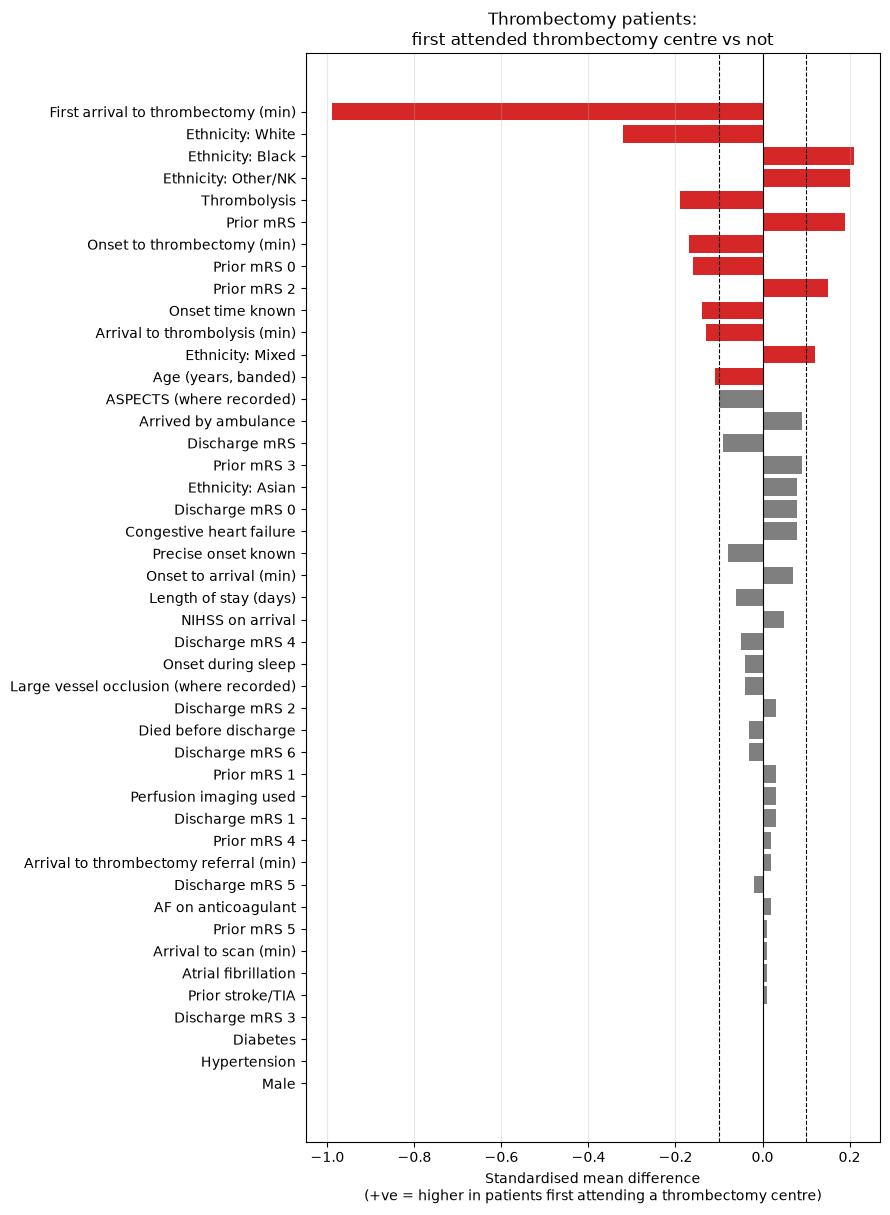

In [12]:
# Plot standardised mean differences (|SMD| > 0.1 is a common threshold for a meaningful imbalance)
# Sort by |SMD| ascending so the largest imbalance appears at the top of the barh chart
plot_data = comparison['SMD'].dropna()
plot_data = plot_data.reindex(plot_data.abs().sort_values().index)
colours = np.where(plot_data.abs() > 0.1, 'tab:red', 'tab:grey')

fig, ax = plt.subplots(figsize=(9, 0.25 * len(plot_data) + 1))
ax.barh(plot_data.index, plot_data.values, color=colours)
for x in (-0.1, 0.1):
    ax.axvline(x, color='k', linestyle='--', linewidth=0.8)
ax.axvline(0, color='k', linewidth=0.8)
ax.set_xlabel('Standardised mean difference\n(+ve = higher in patients first attending a thrombectomy centre)')
ax.set_title('Thrombectomy patients:\nfirst attended thrombectomy centre vs not')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('output/thrombectomy_by_first_centre_smd.png', dpi=300, bbox_inches='tight')
plt.show()

**Results:** 13 characteristics exceed the ±0.1 threshold. In order of size: first arrival to thrombectomy time (−0.99, far larger than any other), White ethnicity (−0.32), Black ethnicity (0.21), Other/not known ethnicity (0.20), thrombolysis (−0.19), prior mRS (0.19), onset to thrombectomy time (−0.17), prior mRS 0 (−0.16), prior mRS 2 (0.15), onset time known (−0.14), arrival to thrombolysis time (−0.13), Mixed ethnicity (0.12) and age (−0.11). All other characteristics are within ±0.1.